# Initialize Dataset

In [15]:
# ============================================================
# PQD-16c DATA INITIALIZATION
# ============================================================

import copy
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

# -------------------- CONFIG --------------------

SEED = 42
DATA_DIR = Path("../dataset/PQD-16c-Data")

TRAIN_CSV = DATA_DIR / "train.csv"
VAL_CSV   = DATA_DIR / "validation.csv"
TEST_CSV  = DATA_DIR / "test.csv"

BATCH_SIZE = 64
EPOCHS = 100
PATIENCE = 15

# -------------------- REPRODUCIBILITY --------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("PQD-16c DATA INITIALIZATION")
print("=" * 60)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# -------------------- LOAD DATA --------------------

train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

LABEL_COLUMN = train_df.columns[0]
SIGNAL_COLUMNS = train_df.columns[1:]

assert val_df.columns.tolist() == train_df.columns.tolist()
assert test_df.columns.tolist() == train_df.columns.tolist()
assert len(SIGNAL_COLUMNS) == 640

# -------------------- EXTRACT --------------------

y_train_raw = train_df[LABEL_COLUMN].values
y_val_raw   = val_df[LABEL_COLUMN].values
y_test_raw  = test_df[LABEL_COLUMN].values

X_train = train_df[SIGNAL_COLUMNS].values.astype(np.float32)
X_val   = val_df[SIGNAL_COLUMNS].values.astype(np.float32)
X_test  = test_df[SIGNAL_COLUMNS].values.astype(np.float32)

# -------------------- LABEL ENCODING --------------------

class_names = sorted(np.unique(y_train_raw))
NUM_CLASSES = len(class_names)

label_to_index = {label: i for i, label in enumerate(class_names)}

y_train = np.array([label_to_index[x] for x in y_train_raw], dtype=np.int64)
y_val   = np.array([label_to_index[x] for x in y_val_raw], dtype=np.int64)
y_test  = np.array([label_to_index[x] for x in y_test_raw], dtype=np.int64)

assert NUM_CLASSES == 16

# -------------------- NORMALIZATION --------------------

train_mean = X_train.mean()
train_std = X_train.std()

X_train = (X_train - train_mean) / train_std
X_val   = (X_val - train_mean) / train_std
X_test  = (X_test - train_mean) / train_std

# -------------------- CNN FORMAT --------------------

# [N, 640] -> [N, 1, 640]

X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_val   = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
X_test  = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train = torch.tensor(y_train, dtype=torch.long)
y_val   = torch.tensor(y_val, dtype=torch.long)
y_test  = torch.tensor(y_test, dtype=torch.long)

# -------------------- DATASETS --------------------

train_dataset = TensorDataset(X_train, y_train)
val_dataset   = TensorDataset(X_val, y_val)
test_dataset  = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

# -------------------- SUMMARY --------------------

print("\nDataset:")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nClasses:", NUM_CLASSES)
print("Normalization mean:", train_mean)
print("Normalization std :", train_std)

print("=" * 60)
print("DATA READY")
print("=" * 60)

PQD-16c DATA INITIALIZATION
Device: cpu

Dataset:
Train: torch.Size([1024, 1, 640]) torch.Size([1024])
Val  : torch.Size([256, 1, 640]) torch.Size([256])
Test : torch.Size([320, 1, 640]) torch.Size([320])

Classes: 16
Normalization mean: 0.00017229914
Normalization std : 0.7113519
DATA READY


# LSTM Evaluation

PQD-16c LSTM EVALUATION
Device     : cpu
Model path : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/lstm_pq_best.pth

Test input shape: torch.Size([320, 640, 1])
Test labels: torch.Size([320])

MODEL LOADED
Architecture : LSTM
Best Epoch   : 9
Best Val Acc : 15.23%
Best Val Loss: 2.5024
Path         : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/lstm_pq_best.pth

LSTM TEST RESULTS
Test Loss     : 2.4868
Test Accuracy : 13.75%
Correct       : 44/320
Wrong         : 276/320

PRECISION / RECALL / F1-SCORE
                        precision    recall  f1-score   support

               Flicker     0.0000    0.0000    0.0000        20
     Flicker+Harmonics     0.0000    0.0000    0.0000        20
           Flicker+Sag     0.0000    0.0000    0.0000        20
         Flicker+Swell     0.2985    1.0000    0.4598        20
             Harmonics     0.0000    0.0000    0.0000        20
   Impulsive Transient     0.0905    0.9500    0.1652        20
          Interruption     0.1

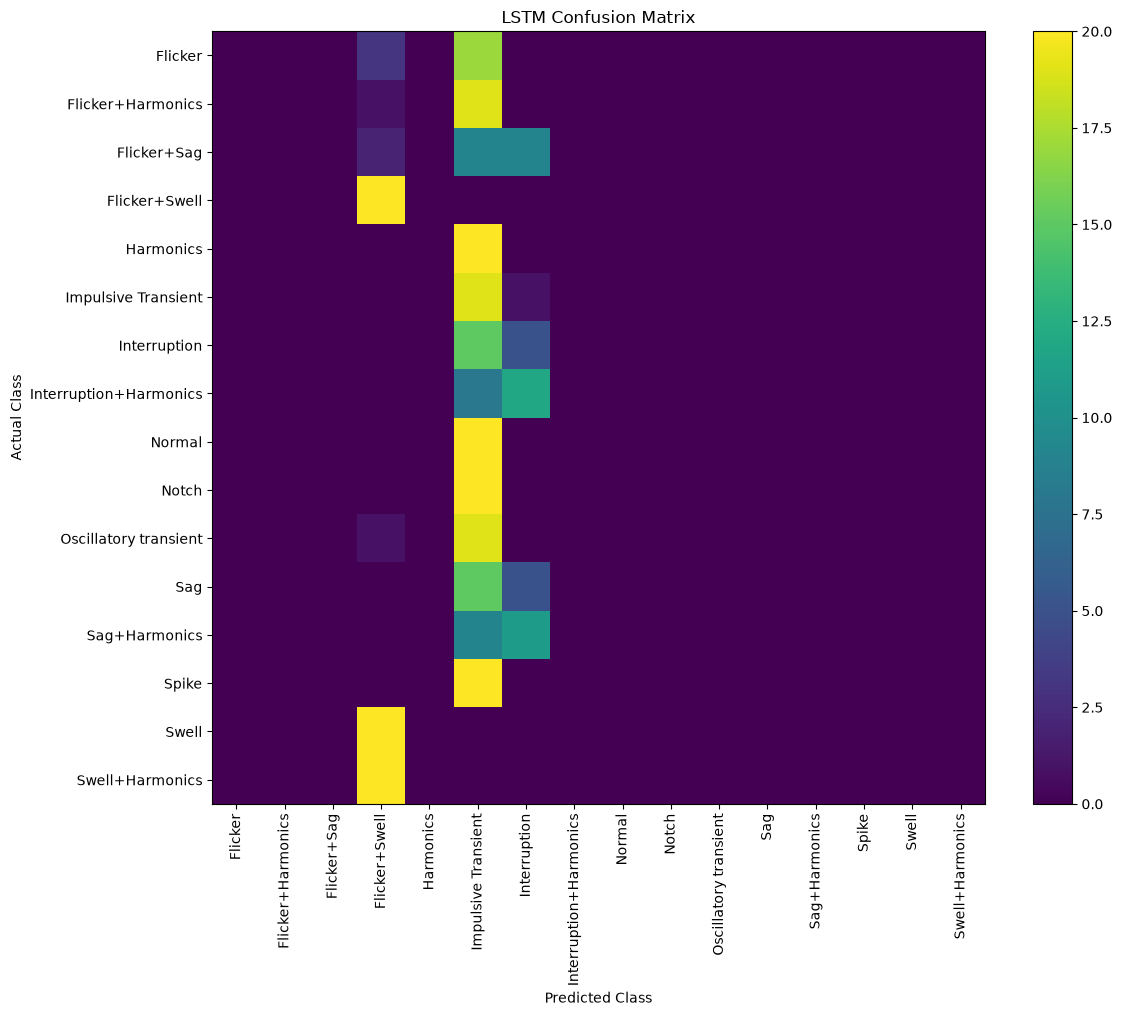

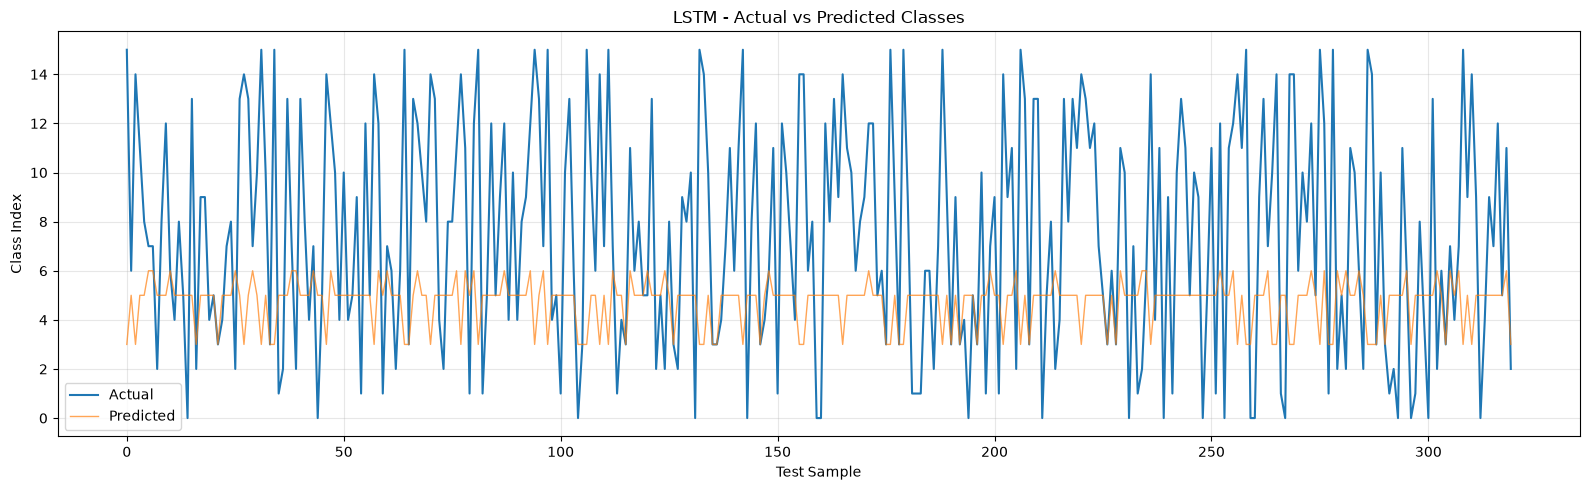

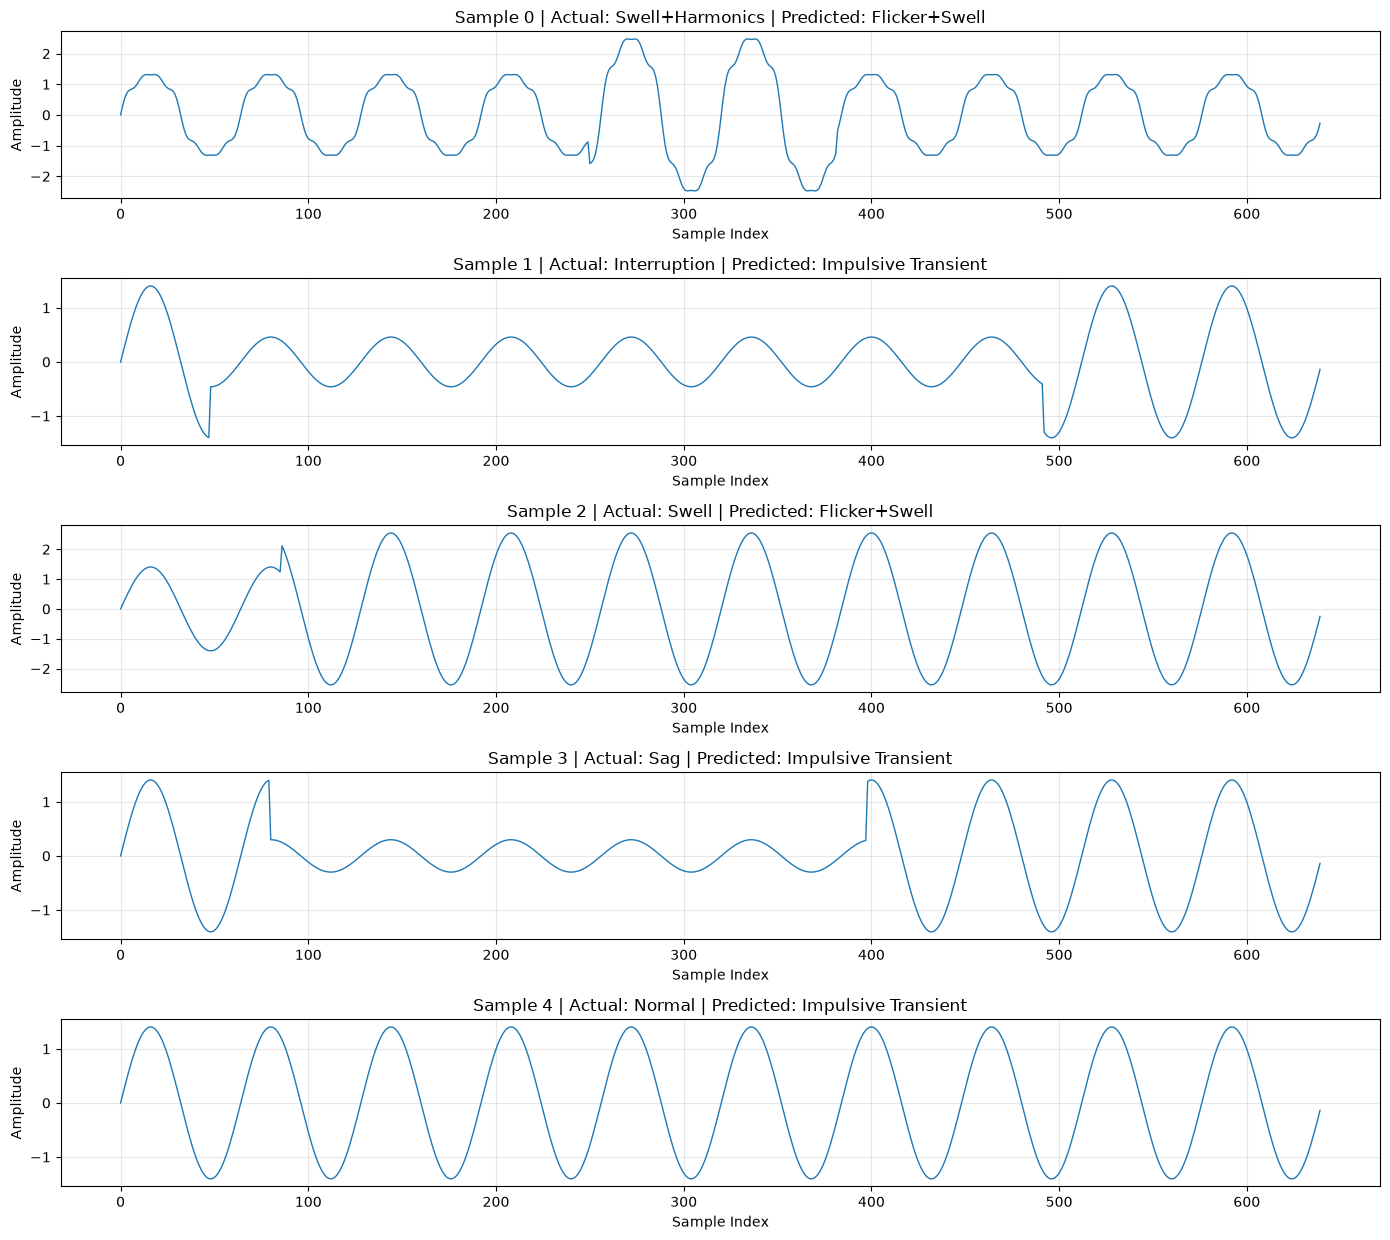

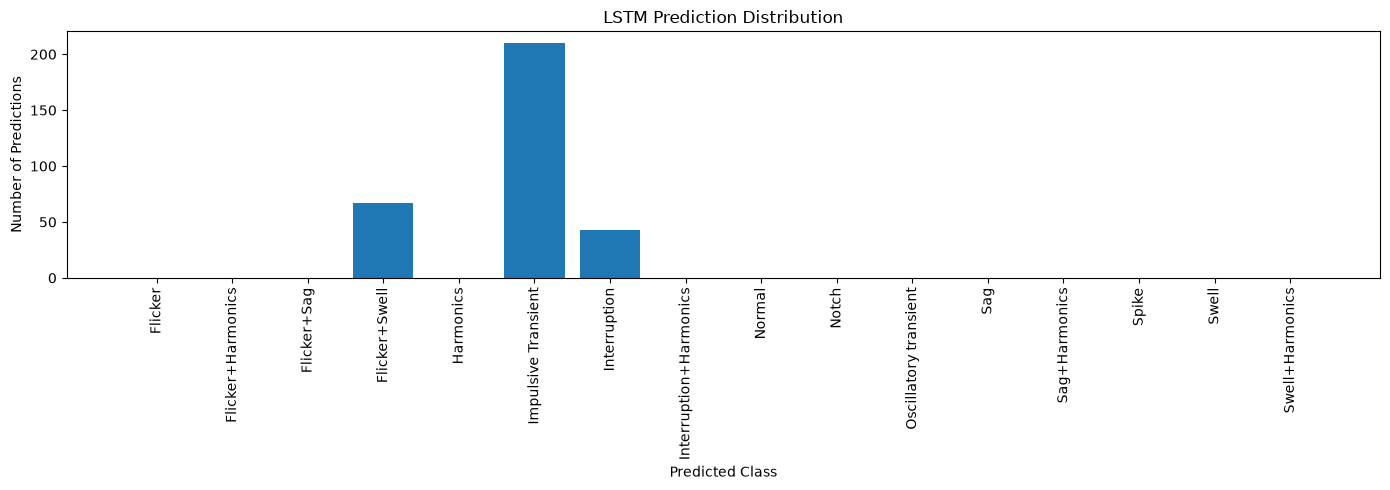


SAMPLE PREDICTIONS
Index   Actual                   Predicted                Confidence  
----------------------------------------------------------------------
0       Swell+Harmonics          Flicker+Swell               31.35%
1       Interruption             Impulsive Transient          7.08%
2       Swell                    Flicker+Swell               31.35%
3       Sag                      Impulsive Transient          7.08%
4       Normal                   Impulsive Transient          7.08%
5       Interruption+Harmonics   Interruption                 7.10%
6       Interruption+Harmonics   Interruption                 7.10%
7       Flicker+Sag              Impulsive Transient          7.08%
8       Normal                   Impulsive Transient          7.08%
9       Sag+Harmonics            Impulsive Transient          7.10%
10      Interruption             Interruption                 7.10%
11      Harmonics                Impulsive Transient          7.10%
12      Normal        

In [16]:
# ============================================================
# PQD-16c LSTM MODEL EVALUATION
#
# Provides:
#   1. Actual vs Predicted outputs
#   2. Test signal visualization
#   3. Confusion matrix
#   4. Precision / Recall / F1-score
#   5. Overall test accuracy
#   6. Prediction distribution
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "../models/lstm_pq_best.pth"
)


# ============================================================
# 2. LSTM MODEL
# ============================================================

class LSTMModel(nn.Module):

    def __init__(self, num_classes=16):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            dropout=0.25
        )

        self.classifier = nn.Sequential(

            nn.Linear(128, 64),

            nn.ReLU(),

            nn.Dropout(0.30),

            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self, x):

        x, _ = self.lstm(x)

        return self.classifier(
            x[:, -1, :]
        )


# ============================================================
# 3. PREPARE TEST DATA
# ============================================================
#
# Data initialization cell gives:
#
#     X_test = [N, 1, 640]
#
# LSTM requires:
#
#     [N, 640, 1]
#
# ============================================================

X_test_eval = X_test

if X_test_eval.dim() == 3:

    X_test_eval = X_test_eval.transpose(
        1, 2
    )

elif X_test_eval.dim() == 2:

    X_test_eval = X_test_eval.unsqueeze(
        -1
    )


y_test_eval = y_test


print("=" * 70)
print("PQD-16c LSTM EVALUATION")
print("=" * 70)

print("Device     :", DEVICE)
print(
    "Model path :",
    MODEL_PATH.resolve()
)

print("=" * 70)

print(
    "\nTest input shape:",
    X_test_eval.shape
)

print(
    "Test labels:",
    y_test_eval.shape
)


# ============================================================
# 4. LOAD MODEL
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model = LSTMModel(
    num_classes=checkpoint["num_classes"]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


print()
print("=" * 70)
print("MODEL LOADED")
print("=" * 70)

print(
    "Architecture :",
    checkpoint.get(
        "architecture",
        "LSTM"
    )
)

print(
    "Best Epoch   :",
    checkpoint.get(
        "best_epoch",
        "N/A"
    )
)

print(
    f"Best Val Acc : "
    f"{checkpoint.get('best_val_accuracy', 0):.2f}%"
)

print(
    f"Best Val Loss: "
    f"{checkpoint.get('best_val_loss', 0):.4f}"
)

print(
    "Path         :",
    MODEL_PATH.resolve()
)


# ============================================================
# 5. PREDICTION
# ============================================================

criterion = nn.CrossEntropyLoss()

all_predictions = []
all_targets = []
all_probabilities = []

test_loss = 0.0


with torch.no_grad():

    inputs = X_test_eval.to(DEVICE)

    targets = y_test_eval.to(DEVICE)

    outputs = model(inputs)

    loss = criterion(
        outputs,
        targets
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    predictions = outputs.argmax(
        dim=1
    )

    test_loss = loss.item()

    all_predictions = (
        predictions
        .cpu()
        .numpy()
    )

    all_targets = (
        targets
        .cpu()
        .numpy()
    )

    all_probabilities = (
        probabilities
        .cpu()
        .numpy()
    )


# ============================================================
# 6. BASIC METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

cm = confusion_matrix(
    all_targets,
    all_predictions
)

report = classification_report(
    all_targets,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)


# ============================================================
# 7. FINAL RESULTS
# ============================================================

print()
print("=" * 70)
print("LSTM TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Correct       : "
    f"{np.sum(all_targets == all_predictions)}/{len(all_targets)}"
)

print(
    f"Wrong         : "
    f"{np.sum(all_targets != all_predictions)}/{len(all_targets)}"
)


# ============================================================
# 8. CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 70)
print("PRECISION / RECALL / F1-SCORE")
print("=" * 70)

print(report)


# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "LSTM Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()


# ============================================================
# 10. ACTUAL VS PREDICTED
# ============================================================

plt.figure(
    figsize=(16, 5)
)

sample_indices = np.arange(
    len(all_targets)
)

plt.plot(
    sample_indices,
    all_targets,
    label="Actual",
    linewidth=1.5
)

plt.plot(
    sample_indices,
    all_predictions,
    label="Predicted",
    linewidth=1.0,
    alpha=0.7
)

plt.xlabel(
    "Test Sample"
)

plt.ylabel(
    "Class Index"
)

plt.title(
    "LSTM - Actual vs Predicted Classes"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. TEST SIGNAL VISUALIZATION
# ============================================================

num_samples_to_plot = min(
    5,
    len(X_test)
)

fig, axes = plt.subplots(
    num_samples_to_plot,
    1,
    figsize=(14, 2.5 * num_samples_to_plot)
)

if num_samples_to_plot == 1:

    axes = [axes]


for i, ax in enumerate(axes):

    signal = (
        X_test[i]
        .squeeze()
        .cpu()
        .numpy()
    )

    ax.plot(
        signal,
        linewidth=1
    )

    actual_name = class_names[
        all_targets[i]
    ]

    predicted_name = class_names[
        all_predictions[i]
    ]

    ax.set_title(
        f"Sample {i} | "
        f"Actual: {actual_name} | "
        f"Predicted: {predicted_name}"
    )

    ax.set_xlabel(
        "Sample Index"
    )

    ax.set_ylabel(
        "Amplitude"
    )

    ax.grid(
        alpha=0.3
    )


plt.tight_layout()

plt.show()


# ============================================================
# 12. PREDICTION DISTRIBUTION
# ============================================================

predicted_counts = np.bincount(
    all_predictions,
    minlength=len(class_names)
)

plt.figure(
    figsize=(14, 5)
)

plt.bar(
    np.arange(len(class_names)),
    predicted_counts
)

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Number of Predictions"
)

plt.title(
    "LSTM Prediction Distribution"
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. SAMPLE PREDICTIONS
# ============================================================

print()
print("=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)

print(
    f"{'Index':<8}"
    f"{'Actual':<25}"
    f"{'Predicted':<25}"
    f"{'Confidence':<12}"
)

print("-" * 70)

for i in range(
    min(20, len(all_targets))
):

    confidence = (
        all_probabilities[i]
        [all_predictions[i]]
        * 100
    )

    print(
        f"{i:<8}"
        f"{class_names[all_targets[i]]:<25}"
        f"{class_names[all_predictions[i]]:<25}"
        f"{confidence:>8.2f}%"
    )


# ============================================================
# 14. COMPLETE
# ============================================================

print()
print("=" * 70)
print("LSTM EVALUATION COMPLETE")
print("=" * 70)

# BiLSTM Evaluation

PQD-16c BiLSTM EVALUATION
Device     : cpu
Model path : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/bilstm_pq_best.pth

Test input shape: torch.Size([320, 640, 1])
Test labels: torch.Size([320])

MODEL LOADED
Architecture : BiLSTM
Best Epoch   : 90
Best Val Acc : 21.48%
Best Val Loss: 1.9678
Path         : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/bilstm_pq_best.pth

BiLSTM TEST RESULTS
Test Loss     : 2.0427
Test Accuracy : 19.06%
Correct       : 61/320
Wrong         : 259/320

PRECISION / RECALL / F1-SCORE
                        precision    recall  f1-score   support

               Flicker     0.0000    0.0000    0.0000        20
     Flicker+Harmonics     0.0000    0.0000    0.0000        20
           Flicker+Sag     0.0000    0.0000    0.0000        20
         Flicker+Swell     0.4211    0.4000    0.4103        20
             Harmonics     0.2899    1.0000    0.4494        20
   Impulsive Transient     0.0000    0.0000    0.0000        20
          Interrupt

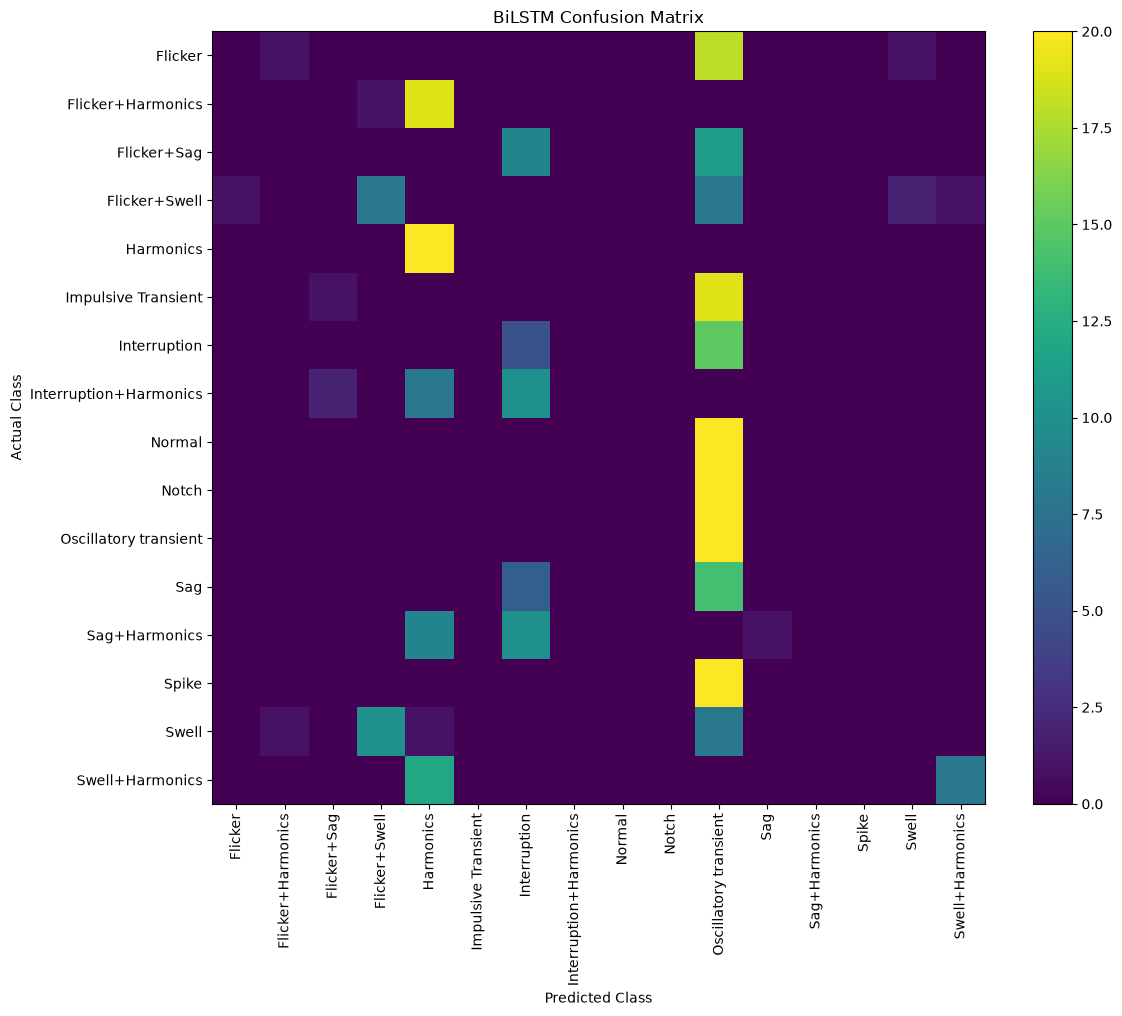

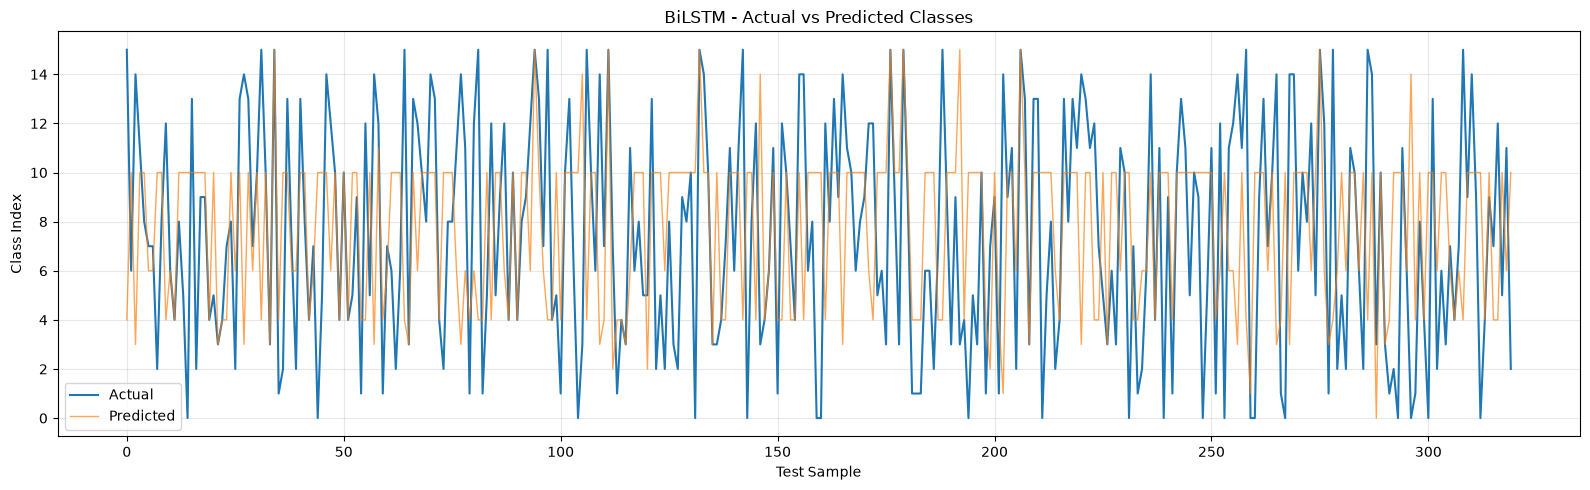

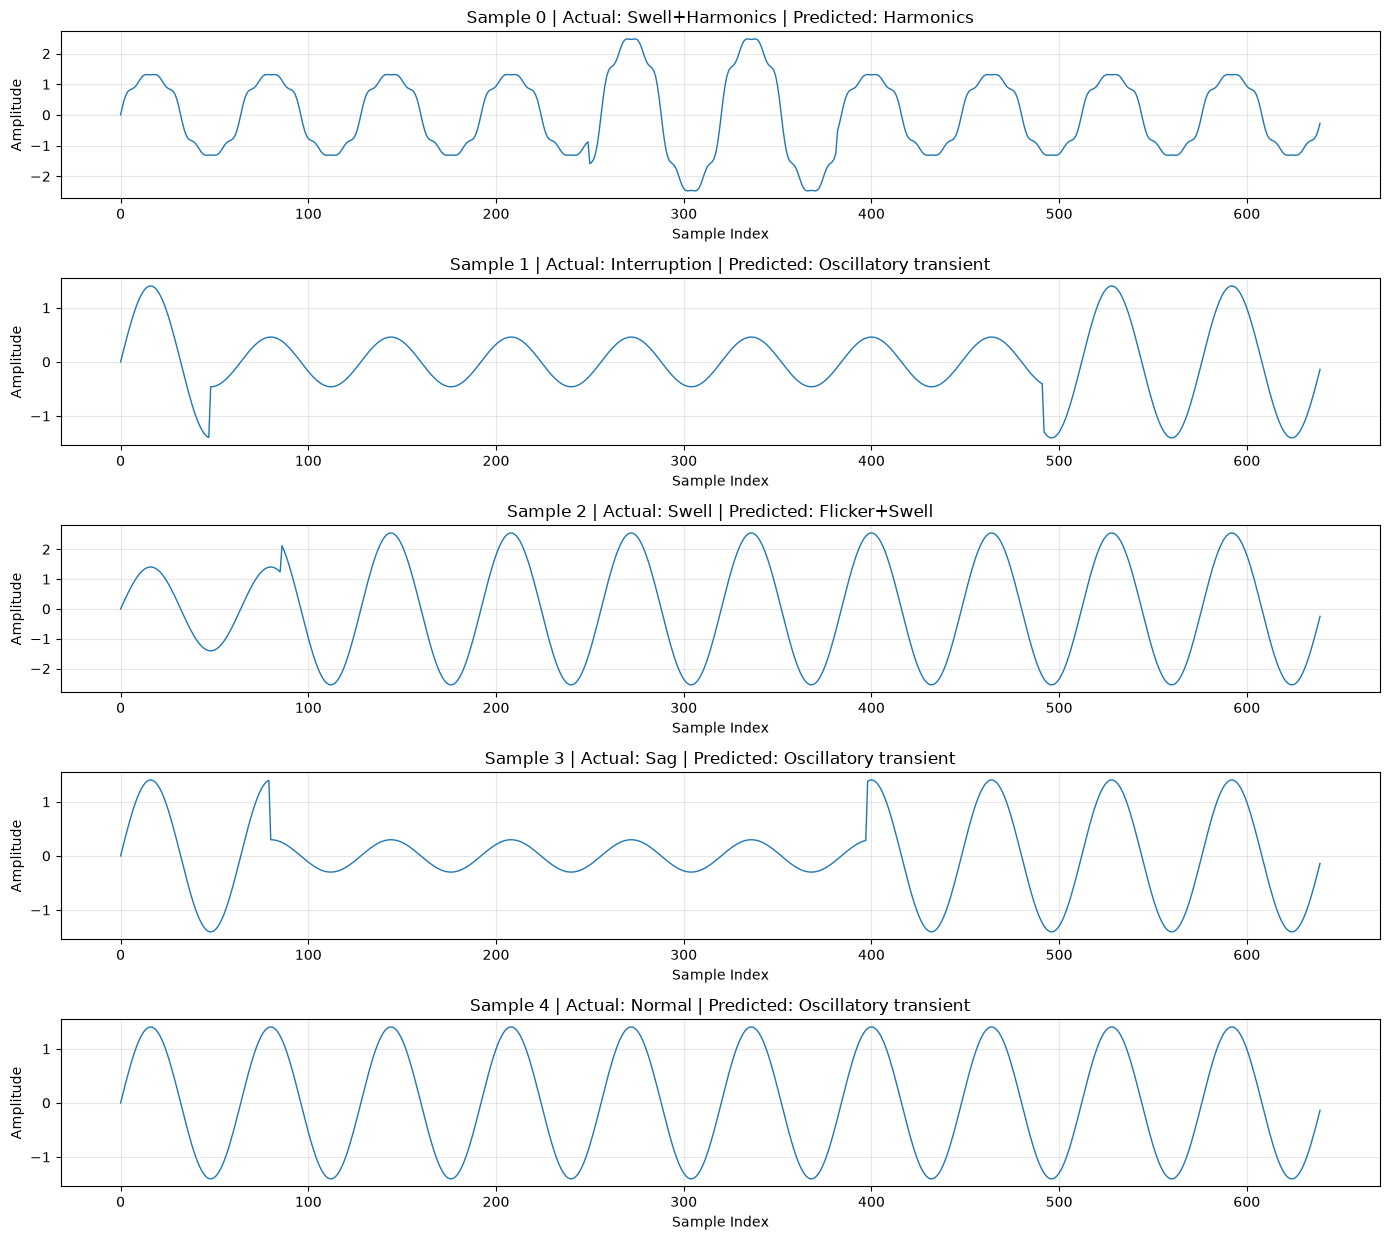

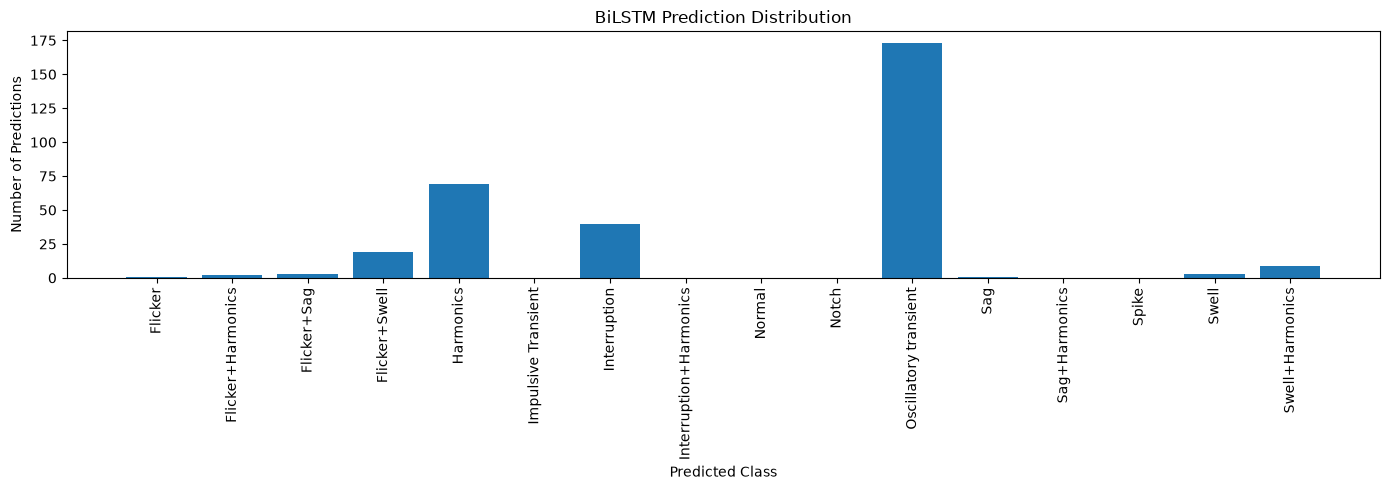


SAMPLE PREDICTIONS
Index   Actual                   Predicted                Confidence  
----------------------------------------------------------------------
0       Swell+Harmonics          Harmonics                   28.65%
1       Interruption             Oscillatory transient       12.07%
2       Swell                    Flicker+Swell               35.50%
3       Sag                      Oscillatory transient       12.08%
4       Normal                   Oscillatory transient       12.08%
5       Interruption+Harmonics   Interruption                23.57%
6       Interruption+Harmonics   Interruption                23.62%
7       Flicker+Sag              Oscillatory transient       12.08%
8       Normal                   Oscillatory transient       12.08%
9       Sag+Harmonics            Harmonics                   28.72%
10      Interruption             Interruption                23.37%
11      Harmonics                Harmonics                   28.74%
12      Normal        

In [17]:
# ============================================================
# PQD-16c BiLSTM MODEL EVALUATION
#
# Provides:
#   1. Actual vs Predicted outputs
#   2. Test signal visualization
#   3. Confusion matrix
#   4. Precision / Recall / F1-score
#   5. Overall test accuracy
#   6. Prediction distribution
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "../models/bilstm_pq_best.pth"
)


# ============================================================
# 2. BiLSTM MODEL
# ============================================================

class BiLSTMModel(nn.Module):

    def __init__(self, num_classes=16):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            dropout=0.25,
            bidirectional=True
        )

        self.classifier = nn.Sequential(

            nn.Linear(256, 64),

            nn.ReLU(),

            nn.Dropout(0.30),

            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self, x):

        x, _ = self.lstm(x)

        return self.classifier(
            x[:, -1, :]
        )


# ============================================================
# 3. PREPARE TEST DATA
# ============================================================
#
# Data initialization cell:
#
#     X_test = [N, 1, 640]
#
# BiLSTM requires:
#
#     [N, 640, 1]
#
# ============================================================

X_test_eval = X_test

if X_test_eval.dim() == 3:

    X_test_eval = X_test_eval.transpose(1, 2)

elif X_test_eval.dim() == 2:

    X_test_eval = X_test_eval.unsqueeze(-1)


y_test_eval = y_test


print("=" * 70)
print("PQD-16c BiLSTM EVALUATION")
print("=" * 70)

print("Device     :", DEVICE)
print(
    "Model path :",
    MODEL_PATH.resolve()
)

print("=" * 70)

print(
    "\nTest input shape:",
    X_test_eval.shape
)

print(
    "Test labels:",
    y_test_eval.shape
)


# ============================================================
# 4. LOAD MODEL
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model = BiLSTMModel(
    num_classes=checkpoint["num_classes"]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


print()
print("=" * 70)
print("MODEL LOADED")
print("=" * 70)

print(
    "Architecture :",
    checkpoint.get(
        "architecture",
        "BiLSTM"
    )
)

print(
    "Best Epoch   :",
    checkpoint.get(
        "best_epoch",
        "N/A"
    )
)

print(
    f"Best Val Acc : "
    f"{checkpoint.get('best_val_accuracy', 0):.2f}%"
)

print(
    f"Best Val Loss: "
    f"{checkpoint.get('best_val_loss', 0):.4f}"
)

print(
    "Path         :",
    MODEL_PATH.resolve()
)


# ============================================================
# 5. PREDICTION
# ============================================================

criterion = nn.CrossEntropyLoss()

with torch.no_grad():

    inputs = X_test_eval.to(DEVICE)
    targets = y_test_eval.to(DEVICE)

    outputs = model(inputs)

    loss = criterion(
        outputs,
        targets
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    predictions = outputs.argmax(
        dim=1
    )

    all_predictions = (
        predictions.cpu().numpy()
    )

    all_targets = (
        targets.cpu().numpy()
    )

    all_probabilities = (
        probabilities.cpu().numpy()
    )

    test_loss = loss.item()


# ============================================================
# 6. METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

cm = confusion_matrix(
    all_targets,
    all_predictions
)

report = classification_report(
    all_targets,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)


# ============================================================
# 7. FINAL RESULTS
# ============================================================

print()
print("=" * 70)
print("BiLSTM TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Correct       : "
    f"{np.sum(all_targets == all_predictions)}/{len(all_targets)}"
)

print(
    f"Wrong         : "
    f"{np.sum(all_targets != all_predictions)}/{len(all_targets)}"
)


# ============================================================
# 8. CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 70)
print("PRECISION / RECALL / F1-SCORE")
print("=" * 70)

print(report)


# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(12, 10))

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "BiLSTM Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()


# ============================================================
# 10. ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(16, 5))

sample_indices = np.arange(
    len(all_targets)
)

plt.plot(
    sample_indices,
    all_targets,
    label="Actual",
    linewidth=1.5
)

plt.plot(
    sample_indices,
    all_predictions,
    label="Predicted",
    linewidth=1.0,
    alpha=0.7
)

plt.xlabel(
    "Test Sample"
)

plt.ylabel(
    "Class Index"
)

plt.title(
    "BiLSTM - Actual vs Predicted Classes"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. TEST SIGNAL VISUALIZATION
# ============================================================

num_samples_to_plot = min(
    5,
    len(X_test)
)

fig, axes = plt.subplots(
    num_samples_to_plot,
    1,
    figsize=(14, 2.5 * num_samples_to_plot)
)

if num_samples_to_plot == 1:
    axes = [axes]


for i, ax in enumerate(axes):

    signal = (
        X_test[i]
        .squeeze()
        .cpu()
        .numpy()
    )

    ax.plot(
        signal,
        linewidth=1
    )

    actual_name = class_names[
        all_targets[i]
    ]

    predicted_name = class_names[
        all_predictions[i]
    ]

    ax.set_title(
        f"Sample {i} | "
        f"Actual: {actual_name} | "
        f"Predicted: {predicted_name}"
    )

    ax.set_xlabel(
        "Sample Index"
    )

    ax.set_ylabel(
        "Amplitude"
    )

    ax.grid(
        alpha=0.3
    )


plt.tight_layout()

plt.show()


# ============================================================
# 12. PREDICTION DISTRIBUTION
# ============================================================

predicted_counts = np.bincount(
    all_predictions,
    minlength=len(class_names)
)

plt.figure(figsize=(14, 5))

plt.bar(
    np.arange(len(class_names)),
    predicted_counts
)

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Number of Predictions"
)

plt.title(
    "BiLSTM Prediction Distribution"
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. SAMPLE PREDICTIONS
# ============================================================

print()
print("=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)

print(
    f"{'Index':<8}"
    f"{'Actual':<25}"
    f"{'Predicted':<25}"
    f"{'Confidence':<12}"
)

print("-" * 70)

for i in range(
    min(20, len(all_targets))
):

    confidence = (
        all_probabilities[i]
        [all_predictions[i]]
        * 100
    )

    print(
        f"{i:<8}"
        f"{class_names[all_targets[i]]:<25}"
        f"{class_names[all_predictions[i]]:<25}"
        f"{confidence:>8.2f}%"
    )


# ============================================================
# 14. COMPLETE
# ============================================================

print()
print("=" * 70)
print("BiLSTM EVALUATION COMPLETE")
print("=" * 70)

# Residual 1D CNN Evaluation

PQD-16c ResCNN EVALUATION
Device     : cpu
Model path : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/cnn_pq_best.pth

Test input shape: torch.Size([320, 1, 640])
Test labels: torch.Size([320])

MODEL LOADED
Architecture : ResCNN
Best Val Acc : 86.72%
Best Val Loss: 0.6004
Path         : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/cnn_pq_best.pth

ResCNN TEST RESULTS
Test Loss     : 0.3111
Test Accuracy : 82.81%
Correct       : 265/320
Wrong         : 55/320

PRECISION / RECALL / F1-SCORE
                        precision    recall  f1-score   support

               Flicker     0.9500    0.9500    0.9500        20
     Flicker+Harmonics     1.0000    1.0000    1.0000        20
           Flicker+Sag     1.0000    0.9500    0.9744        20
         Flicker+Swell     0.9500    0.9500    0.9500        20
             Harmonics     1.0000    1.0000    1.0000        20
   Impulsive Transient     0.7826    0.9000    0.8372        20
          Interruption     0.4000    0.5000

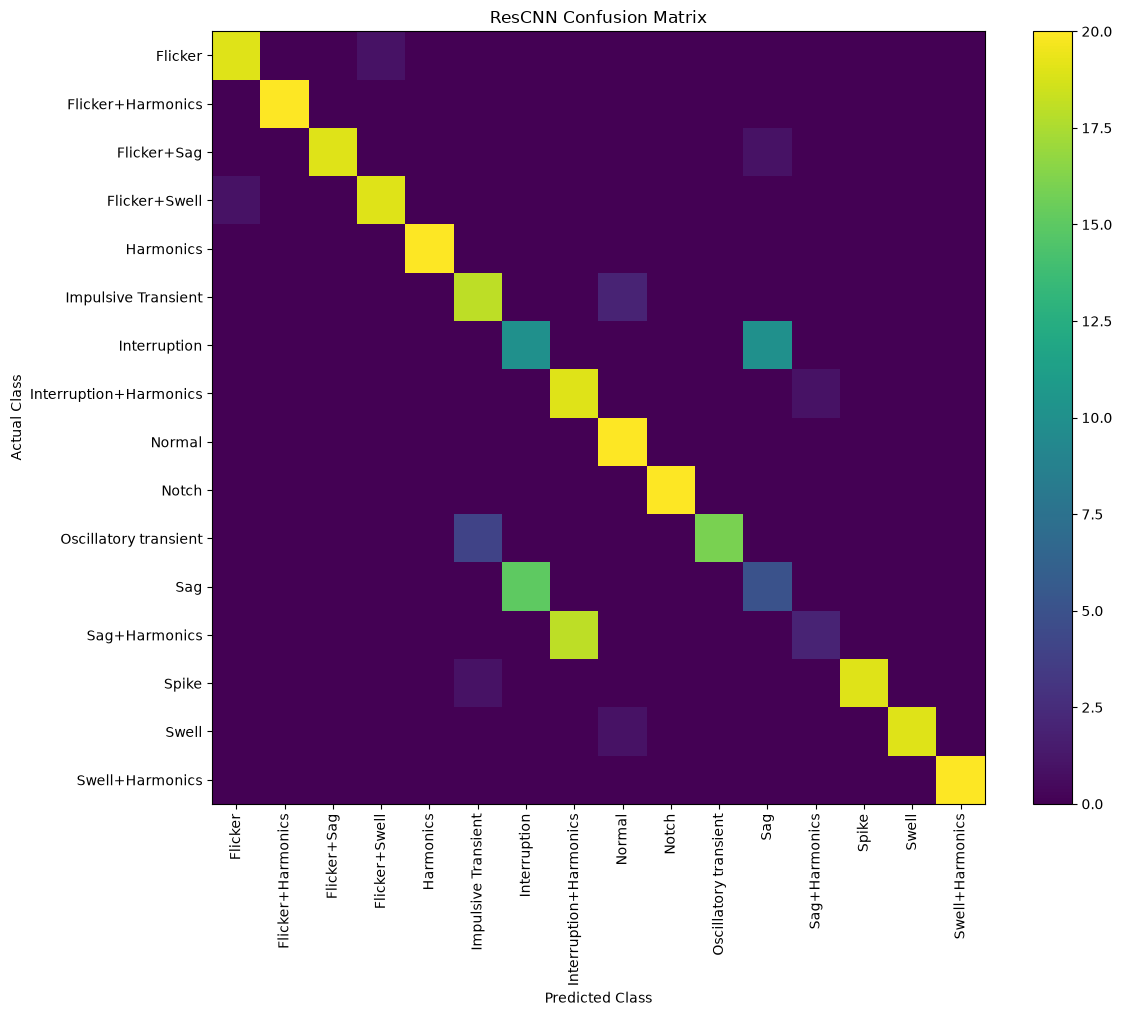

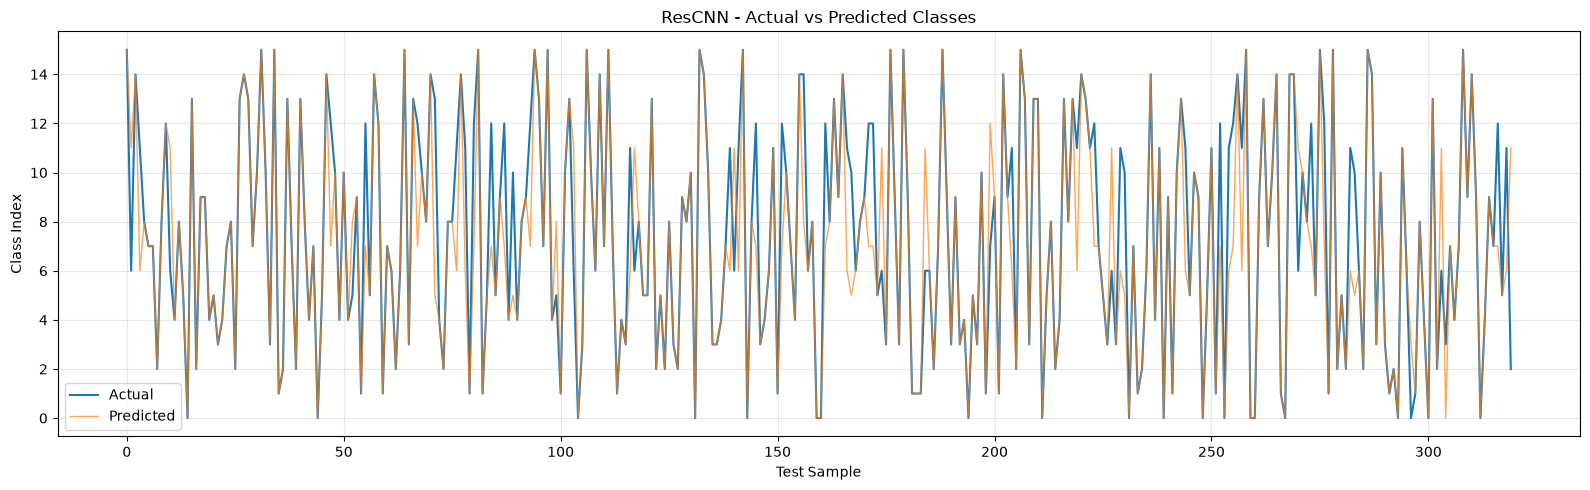

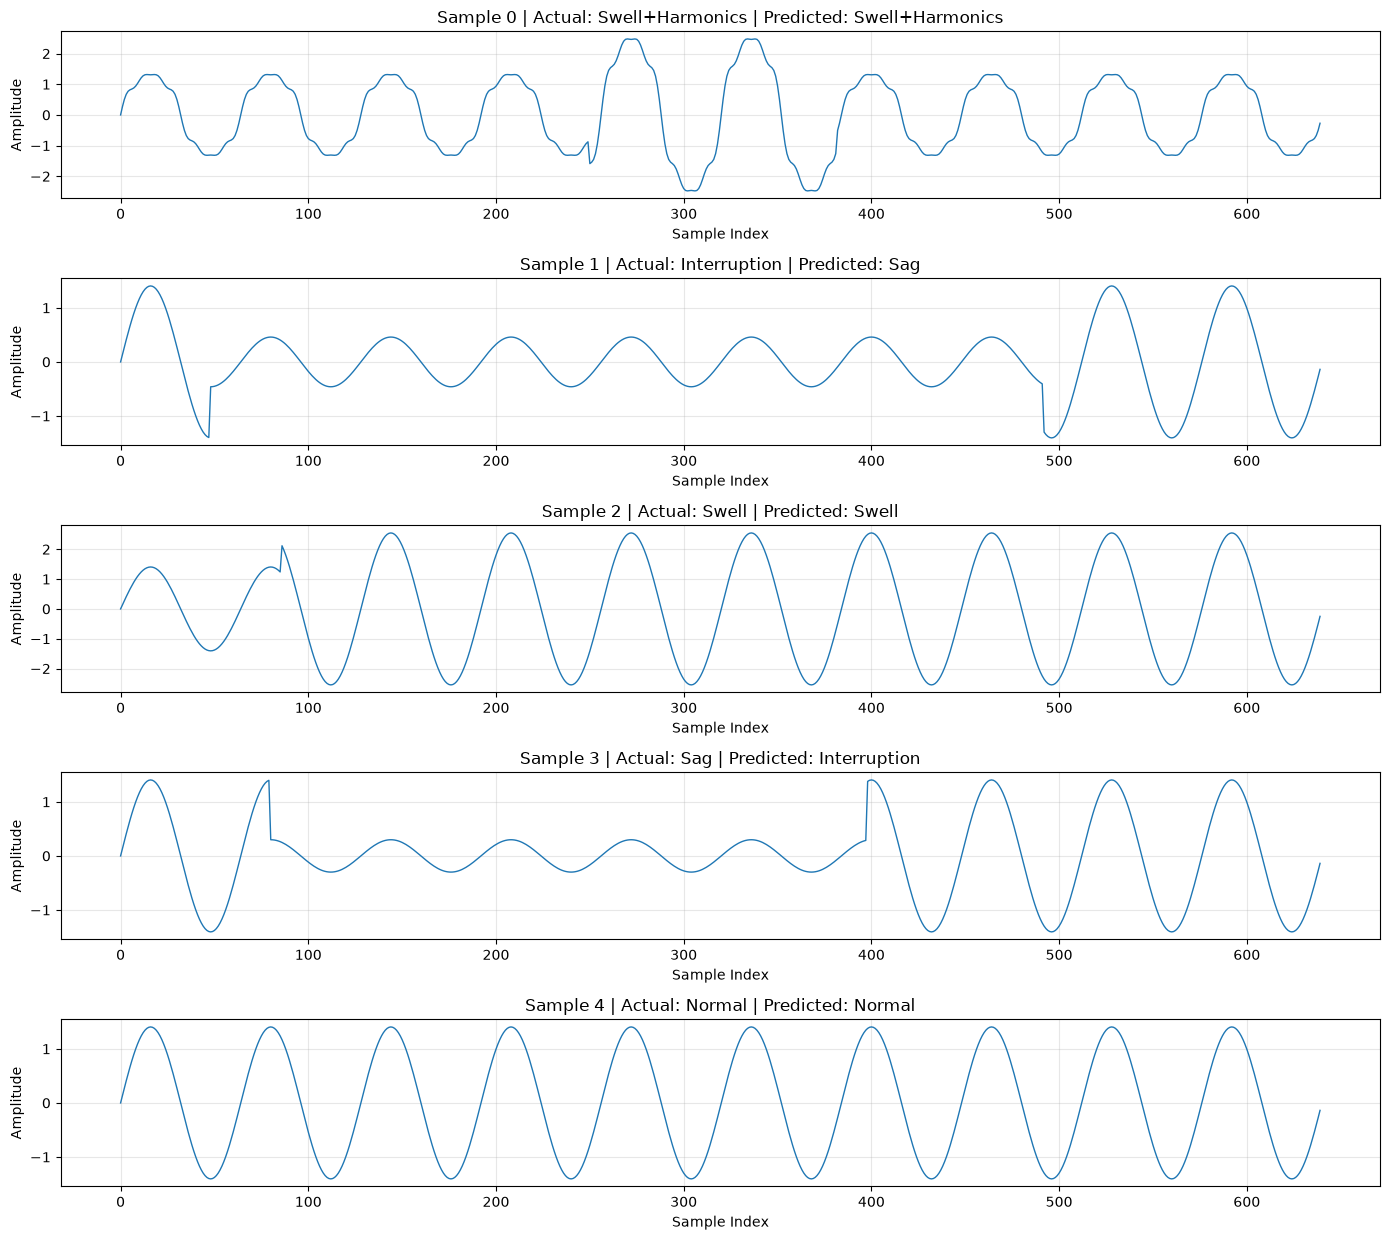

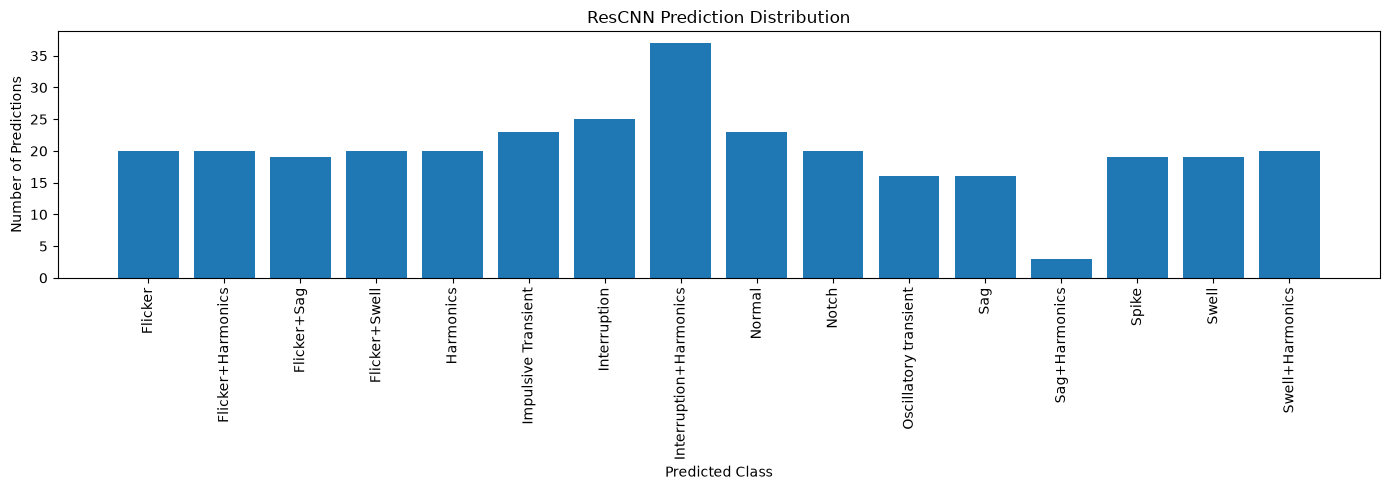


SAMPLE PREDICTIONS
Index   Actual                   Predicted                Confidence  
----------------------------------------------------------------------
0       Swell+Harmonics          Swell+Harmonics             93.07%
1       Interruption             Sag                         53.16%
2       Swell                    Swell                       99.01%
3       Sag                      Interruption                52.55%
4       Normal                   Normal                      94.20%
5       Interruption+Harmonics   Interruption+Harmonics      50.62%
6       Interruption+Harmonics   Interruption+Harmonics      56.22%
7       Flicker+Sag              Flicker+Sag                 93.16%
8       Normal                   Normal                      94.20%
9       Sag+Harmonics            Sag+Harmonics               48.59%
10      Interruption             Sag                         57.96%
11      Harmonics                Harmonics                   97.62%
12      Normal        

In [18]:
# ============================================================
# PQD-16c ResCNN MODEL EVALUATION
#
# Provides:
#   1. Actual vs Predicted outputs
#   2. Test signal visualization
#   3. Confusion matrix
#   4. Precision / Recall / F1-score
#   5. Overall test accuracy
#   6. Prediction distribution
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "../models/cnn_pq_best.pth"
)


# ============================================================
# 2. RESIDUAL BLOCK
# ============================================================

class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        dropout=0.05
    ):

        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size=5,
            stride=stride,
            padding=2,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(
            out_channels
        )

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size=5,
            padding=2,
            bias=False
        )

        self.bn2 = nn.BatchNorm1d(
            out_channels
        )

        self.relu = nn.ReLU(
            inplace=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        if (
            stride != 1
            or in_channels != out_channels
        ):

            self.shortcut = nn.Sequential(

                nn.Conv1d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),

                nn.BatchNorm1d(
                    out_channels
                )
            )

        else:

            self.shortcut = nn.Identity()


    def forward(self, x):

        identity = self.shortcut(x)

        x = self.relu(
            self.bn1(
                self.conv1(x)
            )
        )

        x = self.dropout(x)

        x = self.bn2(
            self.conv2(x)
        )

        return self.relu(
            x + identity
        )


# ============================================================
# 3. RESCNN MODEL
# ============================================================

class CNNPQ(nn.Module):

    def __init__(
        self,
        num_classes=16
    ):

        super().__init__()

        self.stem = nn.Sequential(

            nn.Conv1d(
                1,
                32,
                kernel_size=7,
                padding=3,
                bias=False
            ),

            nn.BatchNorm1d(
                32
            ),

            nn.ReLU(
                inplace=True
            )
        )

        self.features = nn.Sequential(

            ResidualBlock(
                32,
                32,
                stride=2,
                dropout=0.05
            ),

            ResidualBlock(
                32,
                64,
                stride=2,
                dropout=0.05
            ),

            ResidualBlock(
                64,
                96,
                stride=2,
                dropout=0.10
            ),

            ResidualBlock(
                96,
                96,
                stride=1,
                dropout=0.10
            )
        )

        self.pool = nn.AdaptiveAvgPool1d(
            1
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                96,
                48
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                48,
                num_classes
            )
        )


    def forward(self, x):

        x = self.stem(x)

        x = self.features(x)

        x = self.pool(x)

        return self.classifier(x)


# ============================================================
# 4. PREPARE TEST DATA
# ============================================================
#
# Data initialization cell gives:
#
#     X_test = [320, 1, 640]
#
# ResCNN requires:
#
#     [320, 1, 640]
#
# Therefore NO transpose is needed.
#
# ============================================================

X_test_eval = X_test

if X_test_eval.dim() == 2:

    X_test_eval = X_test_eval.unsqueeze(1)


y_test_eval = y_test


print("=" * 70)
print("PQD-16c ResCNN EVALUATION")
print("=" * 70)

print("Device     :", DEVICE)

print(
    "Model path :",
    MODEL_PATH.resolve()
)

print("=" * 70)

print(
    "\nTest input shape:",
    X_test_eval.shape
)

print(
    "Test labels:",
    y_test_eval.shape
)


# ============================================================
# 5. LOAD MODEL
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model = CNNPQ(
    num_classes=checkpoint["num_classes"]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


print()
print("=" * 70)
print("MODEL LOADED")
print("=" * 70)

print(
    "Architecture : ResCNN"
)

print(
    f"Best Val Acc : "
    f"{checkpoint.get('best_val_accuracy', 0):.2f}%"
)

print(
    f"Best Val Loss: "
    f"{checkpoint.get('best_val_loss', 0):.4f}"
)

print(
    "Path         :",
    MODEL_PATH.resolve()
)


# ============================================================
# 6. PREDICTION
# ============================================================

criterion = nn.CrossEntropyLoss()

with torch.no_grad():

    inputs = X_test_eval.to(DEVICE)

    targets = y_test_eval.to(DEVICE)

    outputs = model(inputs)

    loss = criterion(
        outputs,
        targets
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    predictions = outputs.argmax(
        dim=1
    )

    all_predictions = (
        predictions
        .cpu()
        .numpy()
    )

    all_targets = (
        targets
        .cpu()
        .numpy()
    )

    all_probabilities = (
        probabilities
        .cpu()
        .numpy()
    )

    test_loss = loss.item()


# ============================================================
# 7. METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

cm = confusion_matrix(
    all_targets,
    all_predictions
)

report = classification_report(
    all_targets,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)


# ============================================================
# 8. FINAL RESULTS
# ============================================================

print()
print("=" * 70)
print("ResCNN TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Correct       : "
    f"{np.sum(all_targets == all_predictions)}"
    f"/{len(all_targets)}"
)

print(
    f"Wrong         : "
    f"{np.sum(all_targets != all_predictions)}"
    f"/{len(all_targets)}"
)


# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 70)
print("PRECISION / RECALL / F1-SCORE")
print("=" * 70)

print(report)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "ResCNN Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. ACTUAL VS PREDICTED
# ============================================================

plt.figure(
    figsize=(16, 5)
)

sample_indices = np.arange(
    len(all_targets)
)

plt.plot(
    sample_indices,
    all_targets,
    label="Actual",
    linewidth=1.5
)

plt.plot(
    sample_indices,
    all_predictions,
    label="Predicted",
    linewidth=1.0,
    alpha=0.7
)

plt.xlabel(
    "Test Sample"
)

plt.ylabel(
    "Class Index"
)

plt.title(
    "ResCNN - Actual vs Predicted Classes"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. TEST SIGNAL VISUALIZATION
# ============================================================

num_samples_to_plot = min(
    5,
    len(X_test)
)

fig, axes = plt.subplots(
    num_samples_to_plot,
    1,
    figsize=(
        14,
        2.5 * num_samples_to_plot
    )
)

if num_samples_to_plot == 1:

    axes = [axes]


for i, ax in enumerate(axes):

    signal = (
        X_test[i]
        .squeeze()
        .cpu()
        .numpy()
    )

    ax.plot(
        signal,
        linewidth=1
    )

    actual_name = class_names[
        all_targets[i]
    ]

    predicted_name = class_names[
        all_predictions[i]
    ]

    ax.set_title(
        f"Sample {i} | "
        f"Actual: {actual_name} | "
        f"Predicted: {predicted_name}"
    )

    ax.set_xlabel(
        "Sample Index"
    )

    ax.set_ylabel(
        "Amplitude"
    )

    ax.grid(
        alpha=0.3
    )


plt.tight_layout()

plt.show()


# ============================================================
# 13. PREDICTION DISTRIBUTION
# ============================================================

predicted_counts = np.bincount(
    all_predictions,
    minlength=len(class_names)
)

plt.figure(
    figsize=(14, 5)
)

plt.bar(
    np.arange(len(class_names)),
    predicted_counts
)

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Number of Predictions"
)

plt.title(
    "ResCNN Prediction Distribution"
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. SAMPLE PREDICTIONS
# ============================================================

print()
print("=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)

print(
    f"{'Index':<8}"
    f"{'Actual':<25}"
    f"{'Predicted':<25}"
    f"{'Confidence':<12}"
)

print("-" * 70)

for i in range(
    min(20, len(all_targets))
):

    confidence = (
        all_probabilities[i]
        [all_predictions[i]]
        * 100
    )

    print(
        f"{i:<8}"
        f"{class_names[all_targets[i]]:<25}"
        f"{class_names[all_predictions[i]]:<25}"
        f"{confidence:>8.2f}%"
    )


# ============================================================
# 15. COMPLETE
# ============================================================

print()
print("=" * 70)
print("ResCNN EVALUATION COMPLETE")
print("=" * 70)

# CNN-Res-BiLSTM Evaluation

PQD-16c CNN-RES-BiLSTM V2 EVALUATION
Device     : cpu
Model path : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/cnn_res_bilstm_pq.pth

Test input shape: torch.Size([320, 1, 640])
Test labels: torch.Size([320])

MODEL LOADED
Architecture : CNNResBiLSTM
Best Val Acc : 90.62%
Best Val Loss: 0.2482
Path         : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/cnn_res_bilstm_pq.pth

CNN-RES-BiLSTM V2 TEST RESULTS
Test Loss     : 0.2487
Test Accuracy : 85.94%
Correct       : 275/320
Wrong         : 45/320

PRECISION / RECALL / F1-SCORE
                        precision    recall  f1-score   support

               Flicker     0.9524    1.0000    0.9756        20
     Flicker+Harmonics     1.0000    1.0000    1.0000        20
           Flicker+Sag     1.0000    0.9500    0.9744        20
         Flicker+Swell     1.0000    1.0000    1.0000        20
             Harmonics     1.0000    1.0000    1.0000        20
   Impulsive Transient     1.0000    0.9500    0.9744        20
   

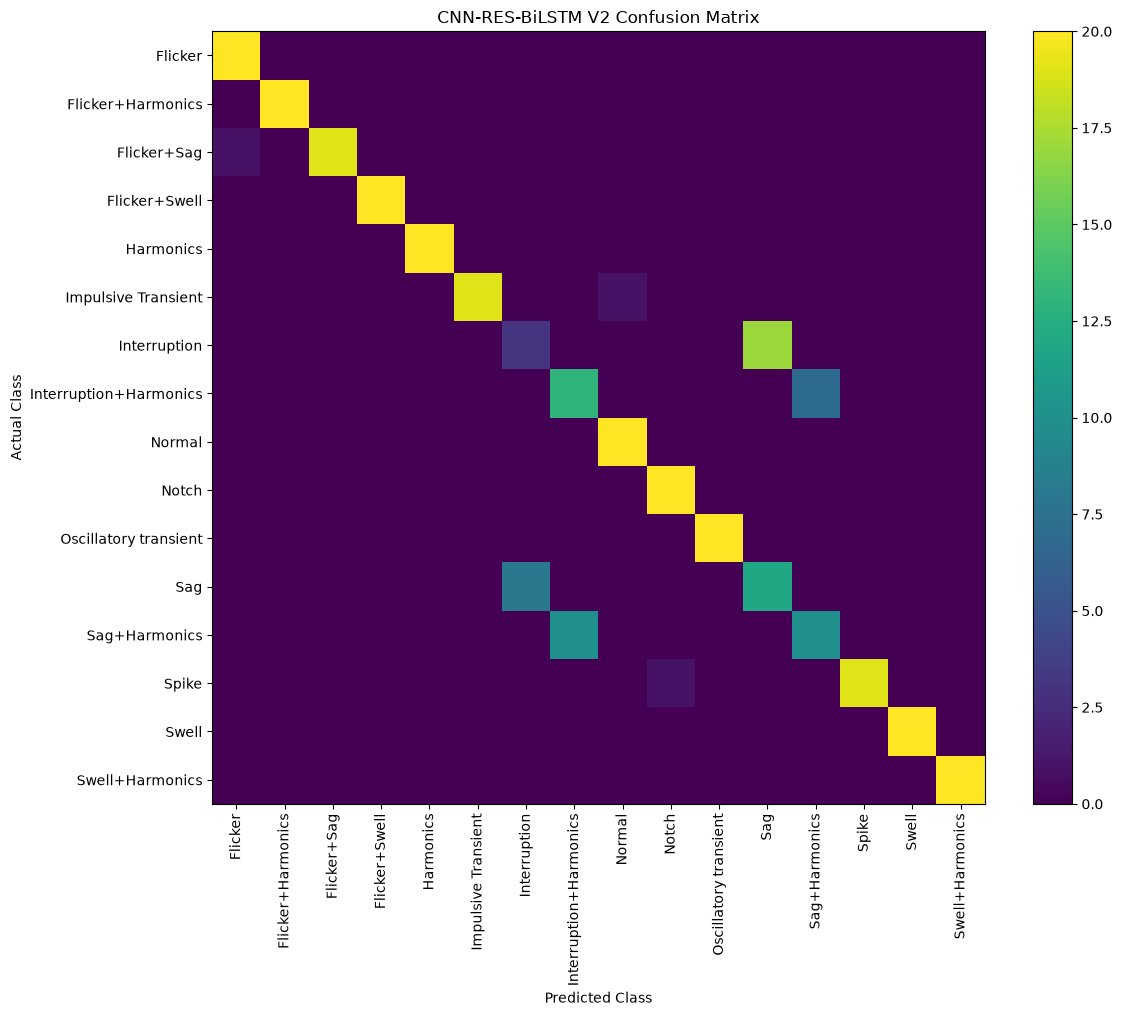

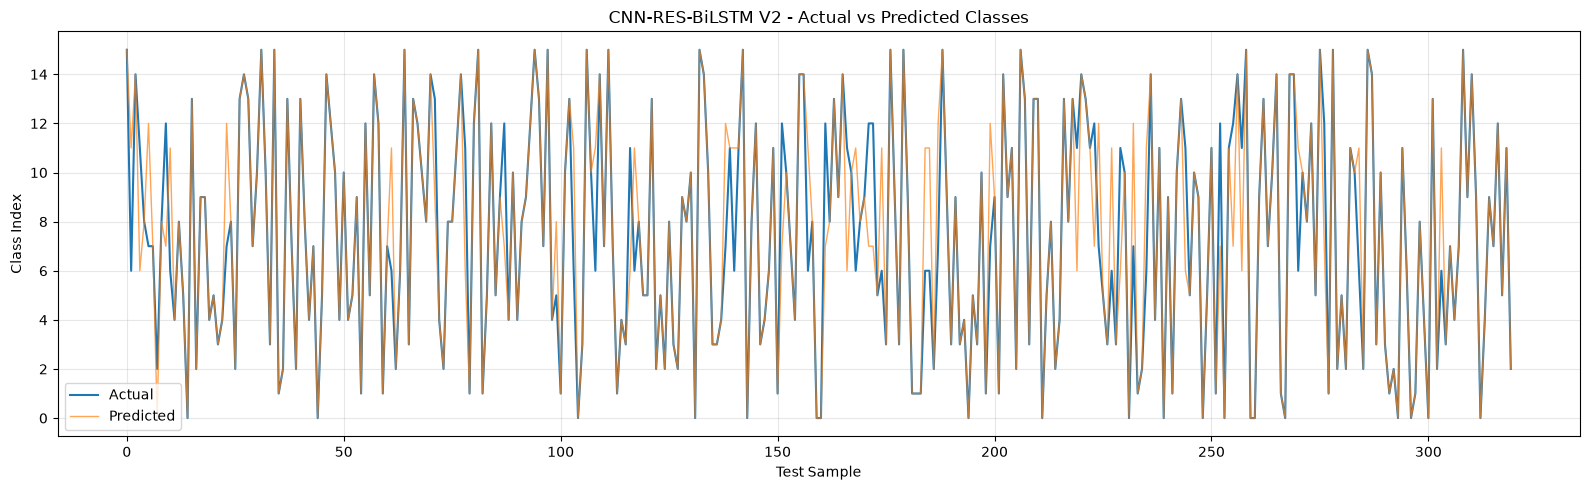

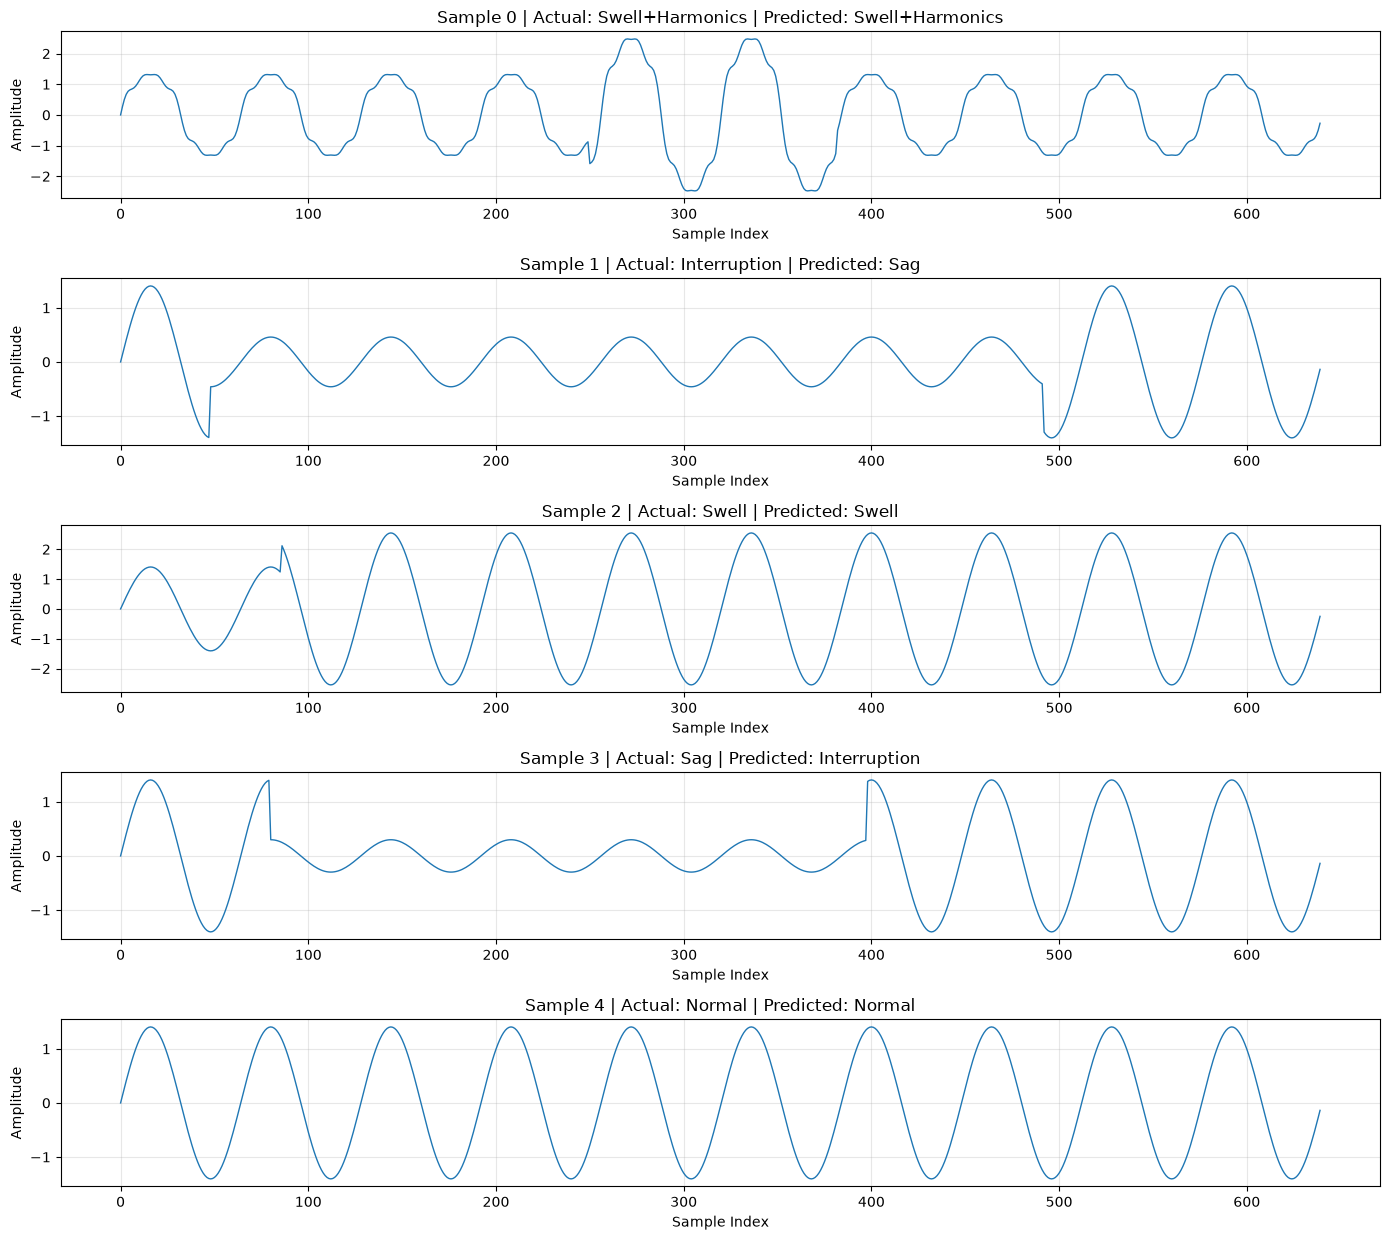

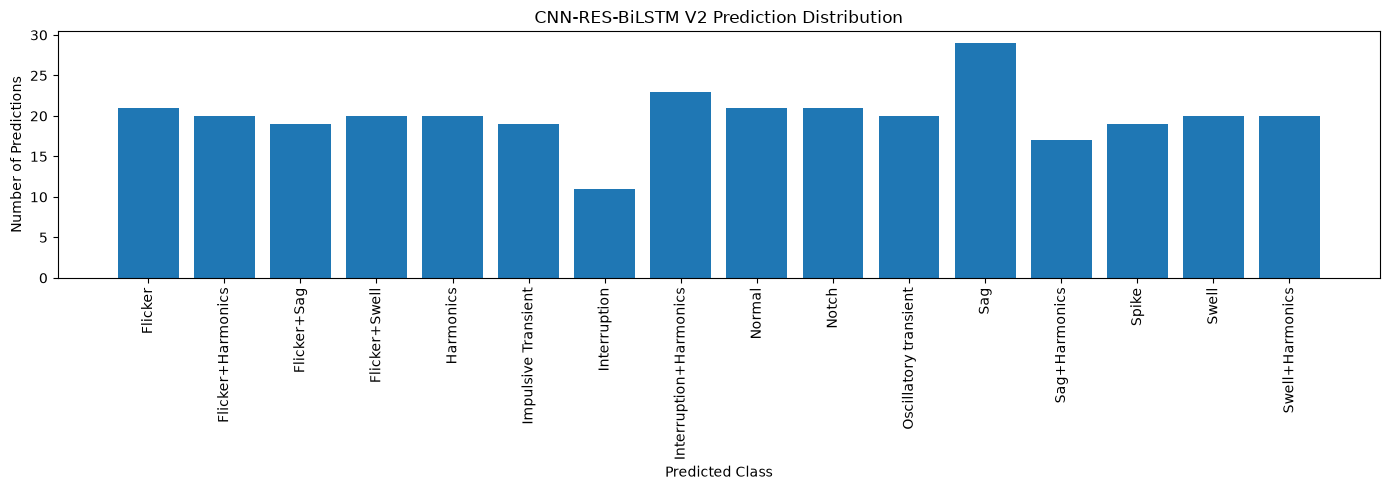


SAMPLE PREDICTIONS
Index   Actual                   Predicted                Confidence  
----------------------------------------------------------------------
0       Swell+Harmonics          Swell+Harmonics             99.63%
1       Interruption             Sag                         56.28%
2       Swell                    Swell                       99.74%
3       Sag                      Interruption                59.38%
4       Normal                   Normal                      95.51%
5       Interruption+Harmonics   Sag+Harmonics               52.83%
6       Interruption+Harmonics   Interruption+Harmonics      56.78%
7       Flicker+Sag              Flicker                     64.80%
8       Normal                   Normal                      95.51%
9       Sag+Harmonics            Interruption+Harmonics      75.96%
10      Interruption             Sag                         52.36%
11      Harmonics                Harmonics                   98.94%
12      Normal        

In [19]:
# ============================================================
# PQD-16c CNN-RES-BiLSTM V2 MODEL EVALUATION
#
# Provides:
#   1. Actual vs Predicted outputs
#   2. Test signal visualization
#   3. Confusion matrix
#   4. Precision / Recall / F1-score
#   5. Overall test accuracy
#   6. Prediction distribution
#   7. Sample predictions with confidence
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "../models/cnn_res_bilstm_pq.pth"
)

print("=" * 70)
print("PQD-16c CNN-RES-BiLSTM V2 EVALUATION")
print("=" * 70)

print("Device     :", DEVICE)
print("Model path :", MODEL_PATH.resolve())

print("=" * 70)

# ============================================================
# 2. RESIDUAL CNN BLOCK
# ============================================================

class ResidualConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=5,
        dilation=1
    ):

        super().__init__()

        padding = (
            (kernel_size - 1) * dilation
        ) // 2

        self.conv1 = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size,
            padding=padding,
            dilation=dilation,
            bias=False
        )

        self.bn1 = nn.BatchNorm1d(
            out_channels
        )

        self.act1 = nn.GELU()

        self.conv2 = nn.Conv1d(
            out_channels,
            out_channels,
            kernel_size,
            padding=padding,
            dilation=dilation,
            bias=False
        )

        self.bn2 = nn.BatchNorm1d(
            out_channels
        )

        if in_channels != out_channels:

            self.skip = nn.Sequential(

                nn.Conv1d(
                    in_channels,
                    out_channels,
                    1,
                    bias=False
                ),

                nn.BatchNorm1d(
                    out_channels
                )
            )

        else:

            self.skip = nn.Identity()

        self.activation = nn.GELU()

    def forward(self, x):

        identity = self.skip(x)

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.act1(x)

        x = self.conv2(x)
        x = self.bn2(x)

        return self.activation(
            x + identity
        )

# ============================================================
# 3. CNN-RES-BiLSTM MODEL
# ============================================================

class CNNResBiLSTM(nn.Module):

    def __init__(
        self,
        num_classes=16
    ):

        super().__init__()

        self.cnn = nn.Sequential(

            nn.Conv1d(
                1,
                32,
                7,
                padding=3,
                bias=False
            ),

            nn.BatchNorm1d(32),

            nn.GELU(),

            ResidualConvBlock(
                32,
                32,
                5,
                1
            ),

            nn.MaxPool1d(2),

            ResidualConvBlock(
                32,
                64,
                5,
                1
            ),

            nn.MaxPool1d(2),

            ResidualConvBlock(
                64,
                128,
                5,
                2
            ),

            nn.MaxPool1d(2),

            ResidualConvBlock(
                128,
                128,
                3,
                2
            )
        )

        self.sequence_norm = nn.LayerNorm(
            128
        )

        self.lstm = nn.LSTM(
            128,
            128,
            num_layers=2,
            batch_first=True,
            dropout=0.25,
            bidirectional=True
        )

        self.attention = nn.Sequential(

            nn.Linear(
                256,
                128
            ),

            nn.Tanh(),

            nn.Linear(
                128,
                1
            )
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                256,
                128
            ),

            nn.GELU(),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        if x.ndim == 4:
            x = x.squeeze(2)

        x = self.cnn(x)

        x = x.transpose(
            1,
            2
        )

        x = self.sequence_norm(x)

        x, _ = self.lstm(x)

        weights = torch.softmax(
            self.attention(x),
            dim=1
        )

        x = torch.sum(
            x * weights,
            dim=1
        )

        return self.classifier(x)

# ============================================================
# 4. PREPARE TEST DATA
# ============================================================
#
# Data initialization cell gives:
#
#     X_test = [320, 1, 640]
#
# CNN-RES-BiLSTM requires:
#
#     [320, 1, 640]
#
# Therefore NO transpose is needed.
#
# ============================================================

X_test_eval = X_test

if X_test_eval.dim() == 2:

    X_test_eval = X_test_eval.unsqueeze(1)

y_test_eval = y_test

print(
    "\nTest input shape:",
    X_test_eval.shape
)

print(
    "Test labels:",
    y_test_eval.shape
)

# ============================================================
# 5. LOAD MODEL
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

model = CNNResBiLSTM(
    num_classes=checkpoint["num_classes"]
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print()
print("=" * 70)
print("MODEL LOADED")
print("=" * 70)

print(
    "Architecture :",
    checkpoint.get(
        "architecture",
        "CNNResBiLSTM"
    )
)

print(
    f"Best Val Acc : "
    f"{checkpoint.get('best_val_accuracy', 0):.2f}%"
)

print(
    f"Best Val Loss: "
    f"{checkpoint.get('best_val_loss', 0):.4f}"
)

print(
    "Path         :",
    MODEL_PATH.resolve()
)

# ============================================================
# 6. PREDICTION
# ============================================================

criterion = nn.CrossEntropyLoss()

with torch.no_grad():

    inputs = X_test_eval.to(DEVICE)

    targets = y_test_eval.to(DEVICE)

    outputs = model(inputs)

    loss = criterion(
        outputs,
        targets
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    predictions = outputs.argmax(
        dim=1
    )

    all_predictions = (
        predictions
        .cpu()
        .numpy()
    )

    all_targets = (
        targets
        .cpu()
        .numpy()
    )

    all_probabilities = (
        probabilities
        .cpu()
        .numpy()
    )

    test_loss = loss.item()

# ============================================================
# 7. METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

cm = confusion_matrix(
    all_targets,
    all_predictions
)

report = classification_report(
    all_targets,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
)

# ============================================================
# 8. FINAL RESULTS
# ============================================================

print()
print("=" * 70)
print("CNN-RES-BiLSTM V2 TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Correct       : "
    f"{np.sum(all_targets == all_predictions)}"
    f"/{len(all_targets)}"
)

print(
    f"Wrong         : "
    f"{np.sum(all_targets != all_predictions)}"
    f"/{len(all_targets)}"
)

# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 70)
print("PRECISION / RECALL / F1-SCORE")
print("=" * 70)

print(report)

# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(12, 10)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    "CNN-RES-BiLSTM V2 Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()

# ============================================================
# 11. ACTUAL VS PREDICTED
# ============================================================

plt.figure(
    figsize=(16, 5)
)

sample_indices = np.arange(
    len(all_targets)
)

plt.plot(
    sample_indices,
    all_targets,
    label="Actual",
    linewidth=1.5
)

plt.plot(
    sample_indices,
    all_predictions,
    label="Predicted",
    linewidth=1.0,
    alpha=0.7
)

plt.xlabel(
    "Test Sample"
)

plt.ylabel(
    "Class Index"
)

plt.title(
    "CNN-RES-BiLSTM V2 - Actual vs Predicted Classes"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

# ============================================================
# 12. TEST SIGNAL VISUALIZATION
# ============================================================

num_samples_to_plot = min(
    5,
    len(X_test)
)

fig, axes = plt.subplots(
    num_samples_to_plot,
    1,
    figsize=(
        14,
        2.5 * num_samples_to_plot
    )
)

if num_samples_to_plot == 1:

    axes = [axes]

for i, ax in enumerate(axes):

    signal = (
        X_test[i]
        .squeeze()
        .cpu()
        .numpy()
    )

    ax.plot(
        signal,
        linewidth=1
    )

    actual_name = class_names[
        all_targets[i]
    ]

    predicted_name = class_names[
        all_predictions[i]
    ]

    ax.set_title(
        f"Sample {i} | "
        f"Actual: {actual_name} | "
        f"Predicted: {predicted_name}"
    )

    ax.set_xlabel(
        "Sample Index"
    )

    ax.set_ylabel(
        "Amplitude"
    )

    ax.grid(
        alpha=0.3
    )

plt.tight_layout()

plt.show()

# ============================================================
# 13. PREDICTION DISTRIBUTION
# ============================================================

predicted_counts = np.bincount(
    all_predictions,
    minlength=len(class_names)
)

plt.figure(
    figsize=(14, 5)
)

plt.bar(
    np.arange(len(class_names)),
    predicted_counts
)

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Number of Predictions"
)

plt.title(
    "CNN-RES-BiLSTM V2 Prediction Distribution"
)

plt.tight_layout()

plt.show()

# ============================================================
# 14. SAMPLE PREDICTIONS
# ============================================================

print()
print("=" * 70)
print("SAMPLE PREDICTIONS")
print("=" * 70)

print(
    f"{'Index':<8}"
    f"{'Actual':<25}"
    f"{'Predicted':<25}"
    f"{'Confidence':<12}"
)

print("-" * 70)

for i in range(
    min(20, len(all_targets))
):

    confidence = (
        all_probabilities[i]
        [all_predictions[i]]
        * 100
    )

    print(
        f"{i:<8}"
        f"{class_names[all_targets[i]]:<25}"
        f"{class_names[all_predictions[i]]:<25}"
        f"{confidence:>8.2f}%"
    )

# ============================================================
# 15. COMPLETE
# ============================================================

print()
print("=" * 70)
print("CNN-RES-BiLSTM V2 EVALUATION COMPLETE")
print("=" * 70)